# 单区域 in-silico perturbation 交互实验

在一个 **16 kb 窗口**里，对一个 BED/坐标指定的区域做反事实干预：

1. 指定一个**被扰动的模态**（`atac` / `rna` / `5mc` / `5hmc`）；
2. 把它在区域内的值改成 **min（0）**、**max（1 或 100）** 或 **random donor（窗口内随机位置）**；
3. 把**其余模态**在该区域的 CpG 位置上用学过的 `[POS-MASK]` token 遮住；
4. 观察被遮模态重构出来的值，以及相对 reference 的 Δ。

**注意**：训练时是“同一位置所有轨道一起遮”；这里让被扰动模态在原位可见，属于**分布外探测**，结果只能当反事实压力测试，不能当模型已验证的能力。

用法：改下面 `CHROM / START / END / PERTURB_TRACK / MODE`，然后重新运行 Cell 5–7。

In [1]:
import os, sys
REPO = "/home/junyichen/code/mmllm"
if os.path.isdir(REPO):
    os.chdir(REPO)
    sys.path.insert(0, REPO)

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

from models import MultiQueryMaskedPretrainingModel
from data import (
    LazyM5cSequenceAtacRnaDataset,
    find_cpg_candidate_positions,
    find_forward_cpg_positions,
)

CHECKPOINT = "output/AMY_MC/cCRE_cpg/2026-10-21-17-19-37_multiquery_4heads_ctxall-others_best_80137.pt"
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
CONTEXT_ORDER = ["5mc", "5hmc", "atac", "rna"]

print("cwd:", os.getcwd())
print("device:", DEVICE)
print("checkpoint exists:", os.path.exists(CHECKPOINT))

cwd: /home/junyichen/code/mmllm
device: cuda:0
checkpoint exists: True


In [2]:
class MultiQueryDataset(torch.utils.data.Dataset):
    def __init__(self, base, track_order):
        self.base = base
        self.track_order = list(track_order)

    def __len__(self):
        return len(self.base)

    def __getitem__(self, idx):
        m5c, sequence_onehot, atac, hm5c, _loss_mask, rna = self.base[idx]
        source = {"5mc": m5c, "atac": atac, "5hmc": hm5c, "rna": rna}
        tracks = [source[name] for name in self.track_order]
        base_ids = sequence_onehot.argmax(dim=-1).long()
        return (*tracks, sequence_onehot, base_ids)


def _first(x):
    return x[0] if isinstance(x, (list, tuple)) else x


def resolve_tracks(args):
    query = list(args["query_tracks"])
    available = {"5mc", "5hmc"}
    if args.get("atac_bw"):
        available.add("atac")
    if args.get("rna_coverage_bw"):
        available.add("rna")
    context = [t for t in CONTEXT_ORDER if t in available and t not in query]
    return query, context


def load_model(path, device):
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    a = ckpt["args"]
    query, context = resolve_tracks(a)
    model = MultiQueryMaskedPretrainingModel(
        seq_len=int(a["target_length"]),
        hidden_dim=int(a["hidden_dim"]),
        use_positional_encoding=bool(a.get("use_positional_encoding", False)),
        num_blocks=int(a["num_blocks"]),
        fusion_type=a["fusion_type"],
        num_queries=len(query),
        num_context_tracks=len(context),
        context_mode=a.get("context_mode", "shared"),
    ).to(device)
    model.load_state_dict(ckpt["model_state_dict"], strict=True)
    model.eval()
    return ckpt, model, query, context


def forward_with_selective_posmask(model, query_tracks, context_tracks, track_tensors, sequence, pos_masks):
    nq, nc = len(query_tracks), len(context_tracks)
    track_hidden = []
    for i, name in enumerate(query_tracks):
        h = model.query_norms[i](model.query_projs[i](track_tensors[i]))
        mask = pos_masks.get(name)
        if mask is not None:
            h = h * (1.0 - mask) + model.query_pos_tokens[i].view(1, 1, -1) * mask
        track_hidden.append(h)
    for k, name in enumerate(context_tracks):
        h = model.context_track_norms[k](model.context_track_projs[k](track_tensors[nq + k]))
        mask = pos_masks.get(name)
        if mask is not None:
            h = h * (1.0 - mask) + model.context_pos_tokens[k].view(1, 1, -1) * mask
        track_hidden.append(h)

    sequence_hidden = model.sequence_norm(model.sequence_proj(sequence))
    context_cache = {}
    preds = []
    for i in range(nq):
        key = tuple(model.context_specs[i])
        context = context_cache.get(key)
        if context is None:
            context = model._fuse_context(sequence_hidden, track_hidden, model.context_specs[i])
            context_cache[key] = context
        hidden = track_hidden[i]
        if model.position_encoding is not None:
            hidden = model.position_encoding(hidden)
        for block in model.blocks:
            hidden = block(hidden, context)
        hidden = model.final_norms[i](hidden)
        preds.append(model.heads[i](hidden))
    return preds


def make_window_df(chrom, start, end, expand_16k=True, target_len=16384, genome_fasta=None):
    import pysam
    fa = pysam.FastaFile(genome_fasta)
    lengths = dict(zip(fa.references, fa.lengths))
    fa.close()
    chrom = str(chrom)
    if not chrom.startswith("chr"):
        chrom = "chr" + chrom
    if chrom not in lengths:
        raise KeyError(f"{chrom} not in {genome_fasta}")
    start, end = sorted((int(start), int(end)))
    center = (start + end) // 2
    if expand_16k:
        ws = center - target_len // 2
        we = ws + target_len
    else:
        ws = start
        we = start + target_len
    chrom_len = lengths[chrom]
    if ws < 0:
        ws, we = 0, target_len
    if we > chrom_len:
        we = chrom_len
        ws = max(0, we - target_len)
    if we - ws < target_len:
        raise ValueError("window too close to chromosome edge")
    rel_start = max(0, start - ws)
    rel_end = min(target_len, end - ws)
    if rel_end <= rel_start:
        raise ValueError("locus outside the 16 kb window")
    return pd.DataFrame([{
        "chr": chrom,
        "start_expanded": int(ws),
        "end_expanded": int(we),
        "start": int(start),
        "end": int(end),
        "center": int(center),
        "name": f"{chrom}:{start}-{end}",
        "rel_start": int(rel_start),
        "rel_end": int(rel_end),
    }])


def load_window(df, ck_args, track_order):
    base = LazyM5cSequenceAtacRnaDataset(
        indices=[0],
        df_dmr=df,
        genome_fasta=ck_args["genome_fasta"],
        m5c_bedgraph=_first(ck_args["m5c_bedgraph"]),
        hm5c_bedgraph=_first(ck_args["hm5c_bedgraph"]),
        atac_bw_path=_first(ck_args["atac_bw"]),
        target_length=int(ck_args["target_length"]),
        mask_mode=ck_args.get("mask_mode", "cpg_forward"),
        atac_scaling=ck_args.get("atac_scaling", "minmax"),
        rna_bw_path=_first(ck_args["rna_coverage_bw"]),
        rna_scaling=ck_args.get("rna_scaling", "minmax"),
        augment_rc=False,
        clip_at_zero=bool(ck_args.get("clip_at_zero", False)),
    )
    ds = MultiQueryDataset(base, track_order)
    item = ds[0]
    tracks = [item[j].unsqueeze(0) for j in range(len(track_order))]
    seq = item[len(track_order)].unsqueeze(0)
    base_ids = item[len(track_order) + 1].unsqueeze(0)
    return tracks, seq, base_ids


def run_locus(ckpt, model, query_tracks, context_tracks, df, perturb_track, mode,
              mask_others=True, max_value=None, seed=7, device="cuda:0"):
    torch.manual_seed(seed)
    np.random.seed(seed)
    ck_args = ckpt["args"]
    track_order = query_tracks + context_tracks
    if perturb_track not in track_order:
        raise ValueError(f"{perturb_track} not in {track_order}")

    tracks, seq, base_ids = load_window(df, ck_args, track_order)
    L = base_ids.shape[1]
    rs = int(df.iloc[0]["rel_start"])
    re = int(df.iloc[0]["rel_end"])
    cpg = find_cpg_candidate_positions(base_ids)
    fwd = find_forward_cpg_positions(base_ids)
    masked_tracks = [t for t in query_tracks if t != perturb_track]
    masked_context = [t for t in context_tracks if t != perturb_track and mask_others]

    pos_masks = {}
    for t in track_order:
        if t == perturb_track or not mask_others:
            pos_masks[t] = None
        else:
            m = torch.zeros(1, L, 1, dtype=torch.float32)
            m[0, rs:re, 0] = cpg[0, rs:re].float()
            pos_masks[t] = m.to(device)

    ref_tracks = [t.to(device) for t in tracks]
    ref_preds = forward_with_selective_posmask(
        model, query_tracks, context_tracks, ref_tracks, seq.to(device), pos_masks
    )

    if max_value is None:
        max_value = 1.0 if perturb_track in ("atac", "rna") else 100.0
    pert_track = tracks[track_order.index(perturb_track)].clone()
    if mode == "min":
        pert_track[0, rs:re, 0] = 0.0
    elif mode == "max":
        pert_track[0, rs:re, 0] = float(max_value)
    elif mode == "random":
        need = re - rs
        off = int(np.random.randint(0, L - need + 1))
        pert_track[0, rs:re, 0] = tracks[track_order.index(perturb_track)][0, off:off + need, 0]
    else:
        raise ValueError(mode)

    pert_tracks = [t.clone().to(device) for t in tracks]
    pert_tracks[track_order.index(perturb_track)] = pert_track.to(device)
    pert_preds = forward_with_selective_posmask(
        model, query_tracks, context_tracks, pert_tracks, seq.to(device), pos_masks
    )

    pred_ref = {t: ref_preds[query_tracks.index(t)][0, :, 0].detach().cpu().numpy() for t in query_tracks}
    pred_pert = {t: pert_preds[query_tracks.index(t)][0, :, 0].detach().cpu().numpy() for t in query_tracks}

    rows = []
    for t in masked_tracks:
        sel = fwd[0, rs:re].numpy()
        if sel.any():
            rr = pred_ref[t][rs:re][sel]
            pp = pred_pert[t][rs:re][sel]
            rows.append({
                "masked_track": t,
                "n_cpg": int(sel.sum()),
                "mean_ref": float(rr.mean()),
                "mean_pert": float(pp.mean()),
                "delta": float(pp.mean() - rr.mean()),
            })
        else:
            rows.append({
                "masked_track": t,
                "n_cpg": 0,
                "mean_ref": np.nan,
                "mean_pert": np.nan,
                "delta": np.nan,
            })
    summary = pd.DataFrame(rows)
    if masked_context:
        print(f"[warn] masked context tracks {masked_context} have no output head")
    return {
        "df": df,
        "locus": df.iloc[0]["name"],
        "track_order": track_order,
        "tracks": [t[0].cpu() for t in tracks],
        "pert_track": pert_track[0].cpu(),
        "perturb_track": perturb_track,
        "mode": mode,
        "max_value": max_value,
        "rel_start": rs,
        "rel_end": re,
        "L": L,
        "pred_ref": pred_ref,
        "pred_pert": pred_pert,
        "fwd_c": fwd[0],
        "summary": summary,
        "masked_tracks": masked_tracks,
        "query_tracks": query_tracks,
        "context_tracks": context_tracks,
    }


def plot_locus(result, zoom_bp=2000):
    """Line version: reference vs perturbed over the 16 kb window."""
    tracks = result["masked_tracks"]
    pert = result["perturb_track"]
    L = result["L"]
    rs, re = result["rel_start"], result["rel_end"]
    x = np.arange(L) / 1000.0
    rows = len(tracks) + 1
    fig, axes = plt.subplots(rows, 2, figsize=(14, 2.6 * rows), squeeze=False)
    x0 = max(0, rs - zoom_bp) / 1000.0
    x1 = min(L, re + zoom_bp) / 1000.0

    for r, t in enumerate(tracks):
        for c, (lo, hi) in enumerate([(0, L / 1000.0), (x0, x1)]):
            ax = axes[r, c]
            ax.plot(x, result["pred_ref"][t], lw=1, label="reference")
            ax.plot(x, result["pred_pert"][t], lw=1, label="perturbed")
            ax.axvspan(rs / 1000.0, re / 1000.0, color="orange", alpha=0.18, label="perturbed interval")
            ax.set_xlim(lo, hi)
            ax.set_ylabel(t)
            ax.grid(alpha=0.2)
            if r == 0:
                ax.set_title("full 16 kb" if c == 0 else f"zoom +/-{zoom_bp} bp")
            if c == 0 and r == 0:
                ax.legend(fontsize=8)

    r = len(tracks)
    orig = result["tracks"][result["track_order"].index(pert)][:, 0].numpy()
    new = result["pert_track"][:, 0].numpy()
    for c, (lo, hi) in enumerate([(0, L / 1000.0), (x0, x1)]):
        ax = axes[r, c]
        ax.plot(x, orig, lw=1, label="original")
        ax.plot(x, new, lw=1, label="perturbed")
        ax.axvspan(rs / 1000.0, re / 1000.0, color="orange", alpha=0.18)
        ax.set_xlim(lo, hi)
        ax.set_ylabel(pert)
        ax.grid(alpha=0.2)
        if c == 0 and r == 0:
            ax.legend(fontsize=8)

    for ax in axes[-1, :]:
        ax.set_xlabel("position in 16 kb window (kb)")
    fig.suptitle(f"{result['locus']} | perturb {pert} ({result['mode']})", y=1.0)
    plt.tight_layout()
    plt.show()

In [3]:
ckpt, model, query_tracks, context_tracks = load_model(CHECKPOINT, DEVICE)
ck_args = ckpt["args"]
print("query_tracks  :", query_tracks)
print("context_tracks:", context_tracks)
print("target_length :", ck_args["target_length"])
print("checkpoint epoch:", ckpt.get("epoch"))

query_tracks  : ['5mc', '5hmc', 'atac', 'rna']
context_tracks: []
target_length : 16384
checkpoint epoch: 30


## 1. 选一个位点

下面默认是 cCRE 示例：`chr1:3,525,624-3,529,624`（4 kb，会按中心扩成 16 kb）。

改 `CHROM / START / END`，或改 `EXPAND_16K=False` 从区域起点直接读 16 kb。

In [4]:
CHROM = "chr1"
START = 3525624
END = 3529624
EXPAND_16K = True

PERTURB_TRACK = "atac"      # atac / rna / 5mc / 5hmc
MODE = "max"                # min / max / random
MASK_OTHERS = True
MAX_VALUE = None            # None -> 1.0 for atac/rna, 100.0 for 5mc/5hmc
SEED = 7

df_locus = make_window_df(
    CHROM, START, END,
    expand_16k=EXPAND_16K,
    target_len=int(ck_args["target_length"]),
    genome_fasta=ck_args["genome_fasta"],
)
df_locus

,chr,start_expanded,end_expanded,start,end,center,name,rel_start,rel_end
0,chr1,3519432,3535816,3525624,3529624,3527624,chr1:3525624-3529624,6192,10192


In [5]:
result = run_locus(
    ckpt, model, query_tracks, context_tracks, df_locus,
    PERTURB_TRACK, MODE,
    mask_others=MASK_OTHERS,
    max_value=MAX_VALUE,
    seed=SEED,
    device=DEVICE,
)
display(result["summary"])

idx = result["track_order"].index(PERTURB_TRACK)
before = result["tracks"][idx][result["rel_start"]:result["rel_end"], 0].mean().item()
after = result["pert_track"][result["rel_start"]:result["rel_end"], 0].mean().item()
print(f"perturbed {PERTURB_TRACK}: mean {before:.4f} -> {after:.4f}")
print(f"interval in window: {result['rel_start']} - {result['rel_end']} bp")

,masked_track,n_cpg,mean_ref,mean_pert,delta
0,5mc,17,26.787592,26.048861,-0.738731
1,5hmc,17,32.150112,33.175533,1.025421
2,rna,17,0.024786,0.026026,0.001240


perturbed atac: mean 0.2037 -> 1.0000
interval in window: 6192 - 10192 bp


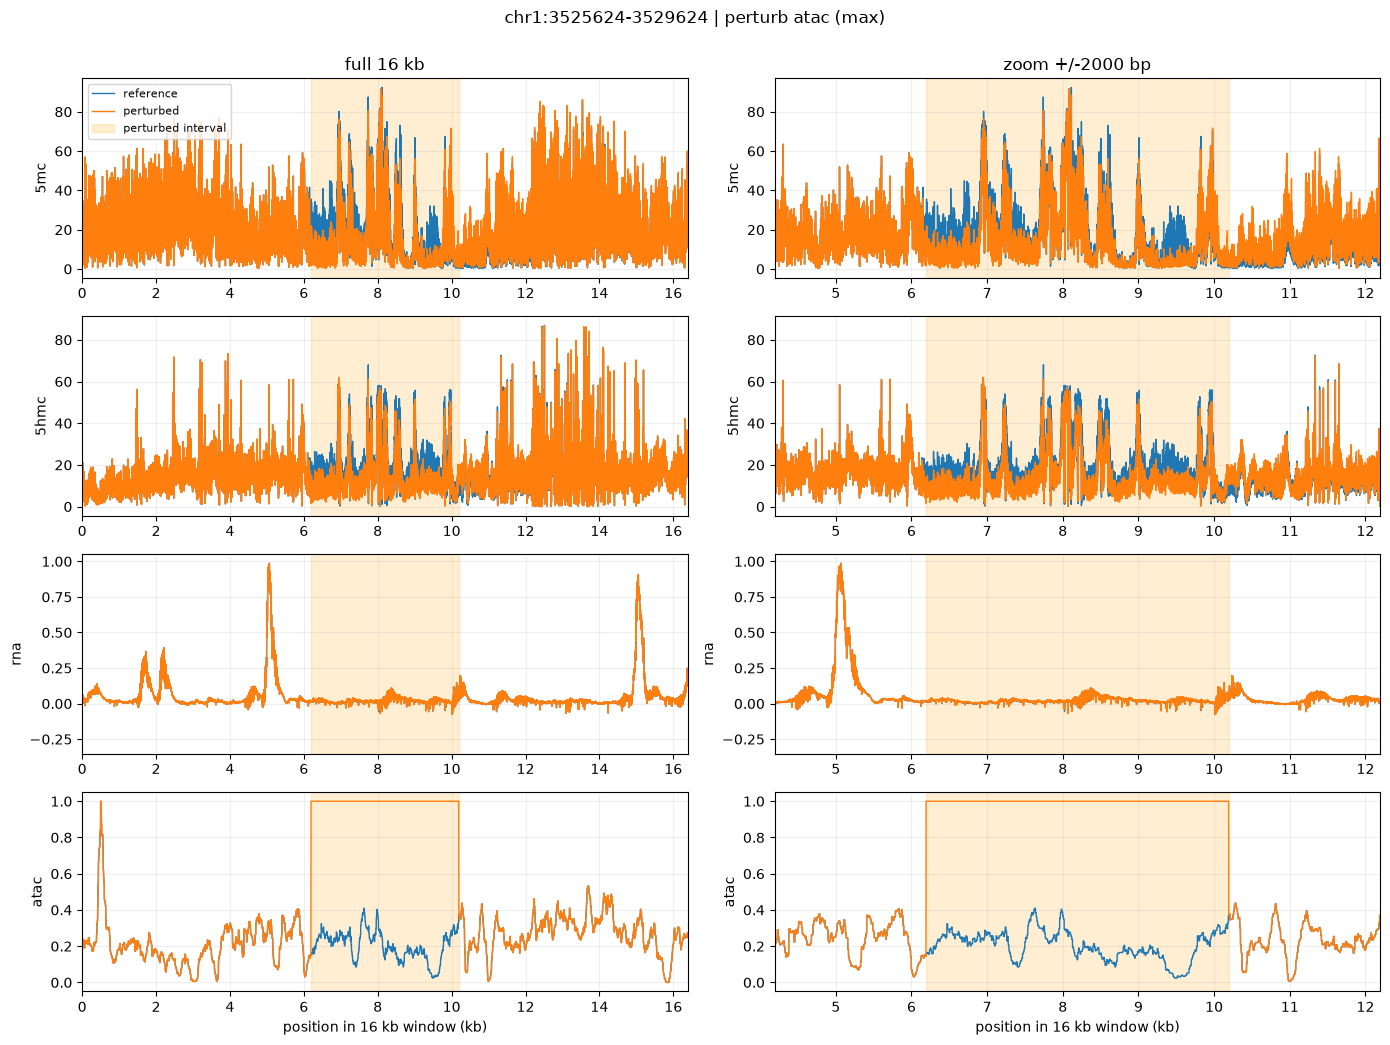

In [6]:
plot_locus(result, zoom_bp=2000)

## 2. 同一区域，比较三种扰动

`random` 在单窗口里用“同一条 track 的随机偏移”作为 donor；如果你要真正的跨区域 donor，用前面那个 `run_xai_region_perturbation.py`（它从 BED 里选另一个区域）。

In [7]:
rows = []
results_by_mode = {}
for mode in ["min", "max", "random"]:
    r = run_locus(
        ckpt, model, query_tracks, context_tracks, df_locus,
        PERTURB_TRACK, mode,
        mask_others=MASK_OTHERS,
        max_value=MAX_VALUE,
        seed=SEED,
        device=DEVICE,
    )
    results_by_mode[mode] = r
    rows.append(r["summary"].assign(mode=mode))

compare = pd.concat(rows, ignore_index=True)
compare

,masked_track,n_cpg,mean_ref,mean_pert,delta,mode
0,5mc,17,26.787592,28.450338,1.662746,min
1,5hmc,17,32.150112,29.101843,-3.048269,min
2,rna,17,0.024786,0.023452,-0.001334,min
3,5mc,17,26.787592,26.048861,-0.738731,max
4,5hmc,17,32.150112,33.175533,1.025421,max
5,rna,17,0.024786,0.026026,0.001240,max
6,5mc,17,26.787592,26.884851,0.097260,random
7,5hmc,17,32.150112,33.259926,1.109814,random
8,rna,17,0.024786,0.024691,-0.000095,random



===== min =====


,masked_track,n_cpg,mean_ref,mean_pert,delta
0,5mc,17,26.787592,28.450338,1.662746
1,5hmc,17,32.150112,29.101843,-3.048269
2,rna,17,0.024786,0.023452,-0.001334


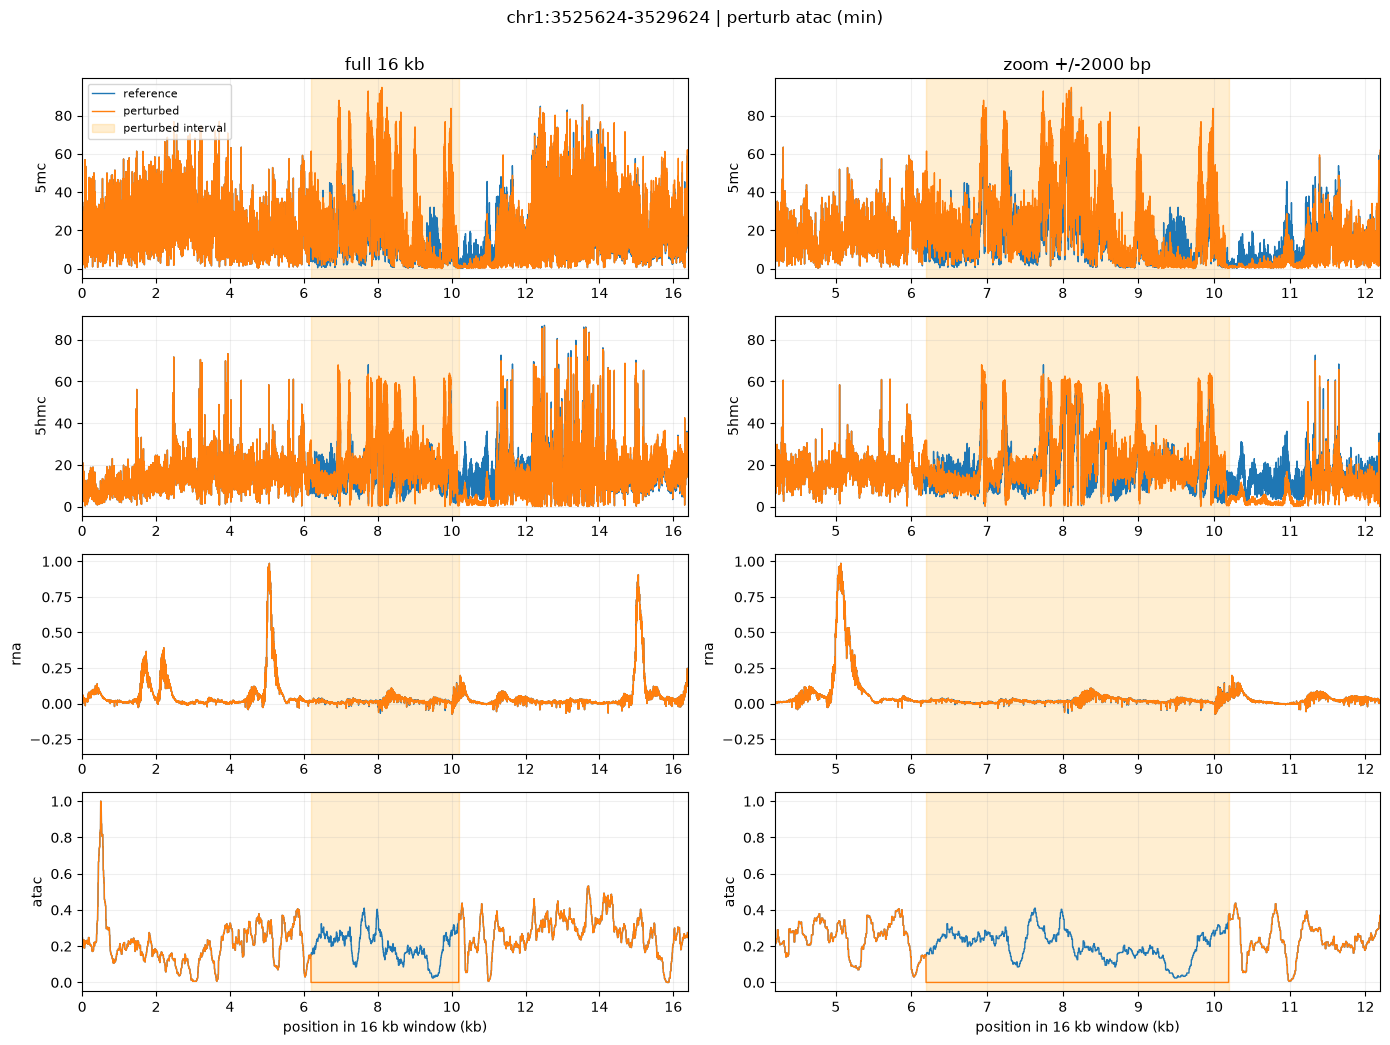


===== max =====


,masked_track,n_cpg,mean_ref,mean_pert,delta
0,5mc,17,26.787592,26.048861,-0.738731
1,5hmc,17,32.150112,33.175533,1.025421
2,rna,17,0.024786,0.026026,0.001240


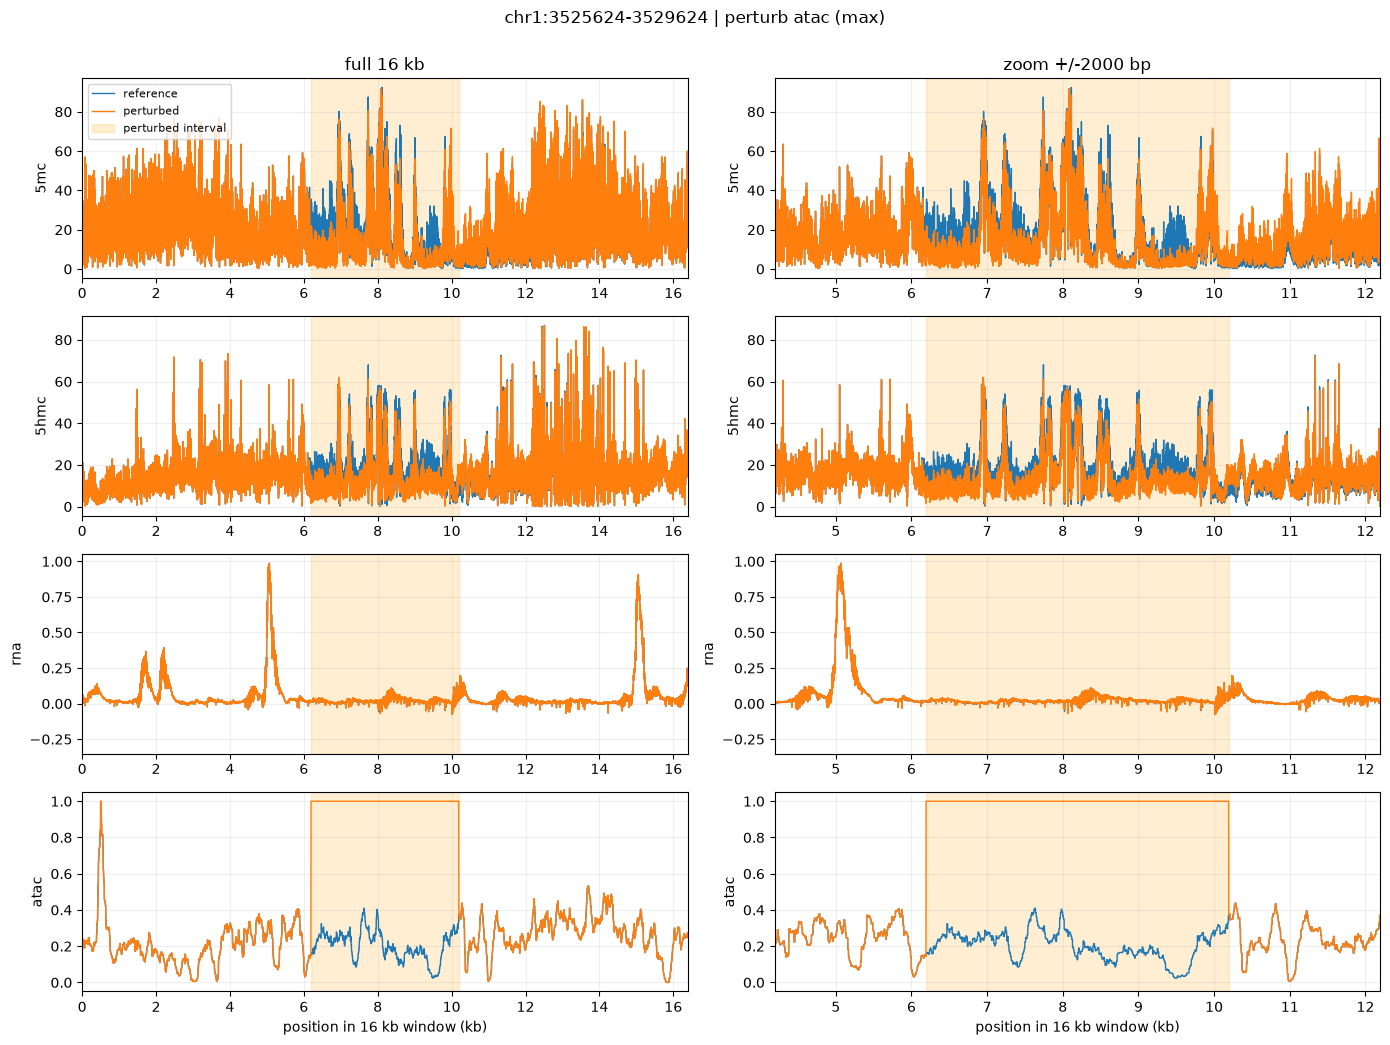


===== random =====


,masked_track,n_cpg,mean_ref,mean_pert,delta
0,5mc,17,26.787592,26.884851,0.097260
1,5hmc,17,32.150112,33.259926,1.109814
2,rna,17,0.024786,0.024691,-0.000095


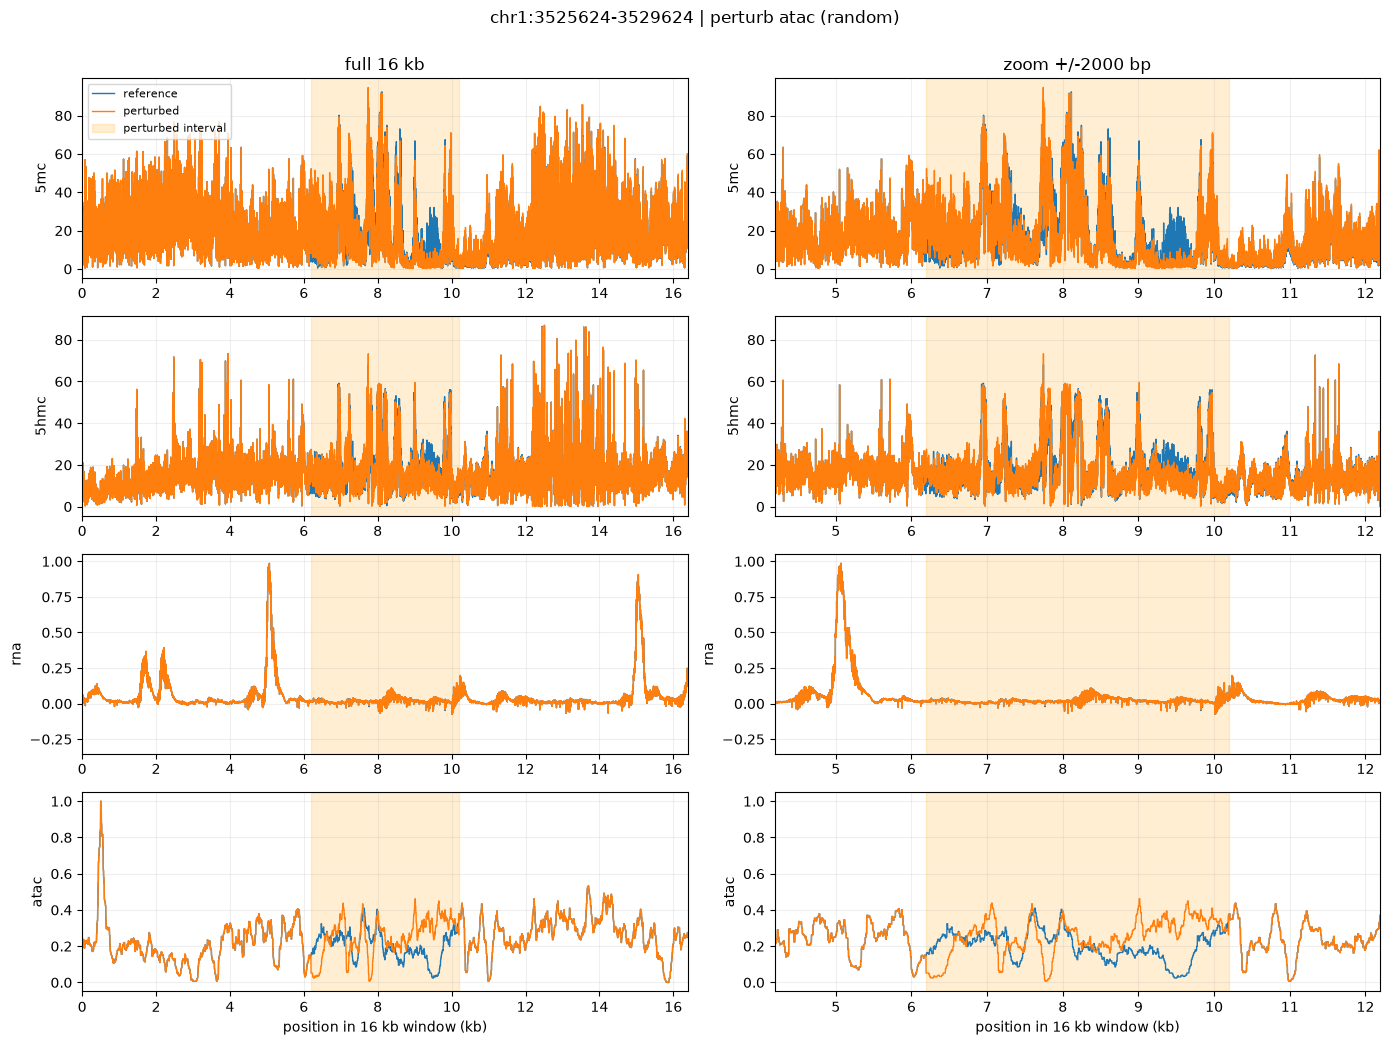

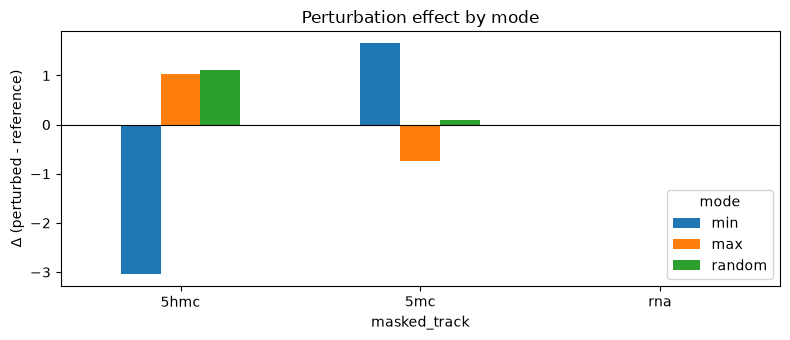

In [8]:
for mode, r in results_by_mode.items():
    print(f"\n===== {mode} =====")
    display(r["summary"])
    plot_locus(r, zoom_bp=2000)

pivot = compare.pivot_table(index="masked_track", columns="mode", values="delta")
pivot = pivot.reindex(columns=["min", "max", "random"])
ax = pivot.plot(kind="bar", figsize=(8, 3.5))
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Δ (perturbed - reference)")
ax.set_title("Perturbation effect by mode")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 3. 试另一个位点 / 另一个模态

- 改 Cell 5 的 `CHROM/START/END`，重跑 Cell 5–7；
- 改 `PERTURB_TRACK` 为 `5hmc`、`5mc` 或 `rna`；
- 改 `MODE` 为 `min` / `max` / `random`；
- 2 头模型（5mC/5hmC 两个头，ATAC/RNA 是 context）也能跑，但被遮的 context 没有输出头，只有 5mC/5hmC 会被画出来。

**解释时记住**：模型训练时是“所有轨道同一位置一起遮”；这里让被扰动模态在原位可见，是分布外探测。Δ 的方向和幅度可以看，但不能直接当生物学因果。